In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df = pd.read_csv("../../course_assignments/homework9/noisy_curvefit_data.csv")
print(df.head())
print(df.shape)
#shape is rectangle 100 rows 8 cols
print(df.tail())
#col names are x, y noise 1 2 3 4 and 5

          x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
0 -1.000000  11.624419   8.296963  12.201067   7.811725   3.155566
1 -0.929293  10.377466   9.674440  12.198084   8.275006   7.518855
2 -0.858586  10.585100   9.251983  13.186565  12.926586   9.963630
3 -0.787879  10.913928   7.786344  12.552304  11.832379   9.625801
4 -0.717172   8.640287   8.551869   4.741432   8.790834   6.624113
(100, 6)
           x  y_noise_1  y_noise_2  y_noise_3  y_noise_4  y_noise_5
95  5.717172  -1.411918   0.822231  -2.027132  -1.825106   2.746147
96  5.787879   0.344879  -1.718956   2.747559  -6.803779  -5.137472
97  5.858586   0.307133   0.353528   0.967976   5.461567  -0.905616
98  5.929293   0.048657   0.159961   2.482130  -0.414616  -4.334548
99  6.000000  -0.193438  -2.244792   1.930035   4.992414  -6.872850


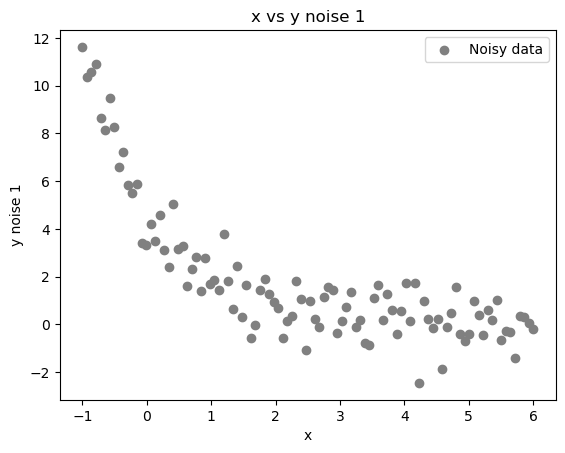

In [18]:
plt.scatter(df["x"], df["y_noise_1"], color="gray", label="Noisy data")
plt.xlabel("x")
plt.ylabel("y noise 1")
plt.title("x vs y noise 1")
plt.legend()

plt.show()

Fit: y = 4.714813879149369 * e^(- 0.9183078513717071 * x)


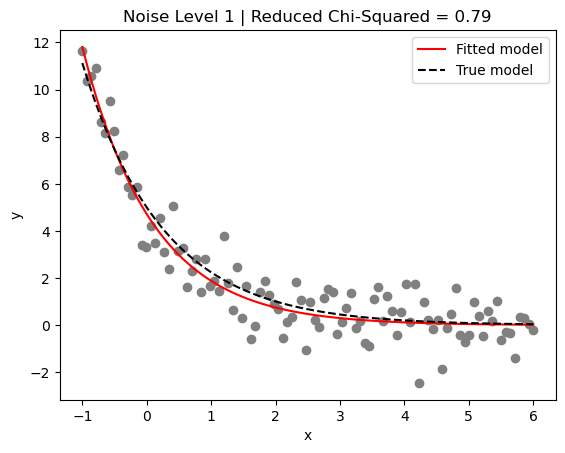

In [28]:
x = df["x"]
y_noise_1 = df["y_noise_1"]

def model(x, A, k):
    return A * np.exp(-k * x)
    
popt, pcov = curve_fit(model, x, y_noise_1, p0=[1, 1])

A_fit, k_fit = popt

print("Fit: y =", A_fit, "* e^(-", k_fit, "* x)")

residuals = y_noise_1 - model(x, A_fit, k_fit)
chi2 = np.sum(residuals**2)
dof = len(x) - len(popt)  # number of points minus number of parameters (2)
chi2_reduced = chi2 / dof

plt.scatter(x, y_noise_1, color="gray")
plt.plot(x, model(x, A_fit, k_fit), color="red", label="Fitted model")
plt.plot(x, model(x, 5, 0.8), color="black", linestyle="--", label="True model")

plt.xlabel("x")
plt.ylabel("y")
plt.title(f"Noise Level 1 | Reduced Chi-Squared = {chi2_reduced:.2f}")
plt.legend()

plt.show()

#the red and black seem to converge
#it increases since more scatter causes bigger residuals.

In [34]:
results_df = pd.DataFrame({
    "Noise level": [1, 2, 3, 4, 5],
    "A fit": [A_fit, 0, 0, 0, 0],
    "k fit": [k_fit, 0, 0, 0, 0],
    "Reduced chi-squared": [chi2_reduced, 0, 0, 0, 0],
})

df.to_csv("noisy_parameters.csv", index=False)
print(results_df)

   Noise level     A fit     k fit  Reduced chi-squared
0            1  4.714814  0.918308             0.790673
1            2  0.000000  0.000000             0.000000
2            3  0.000000  0.000000             0.000000
3            4  0.000000  0.000000             0.000000
4            5  0.000000  0.000000             0.000000
